# Laboratorio 1. ¿Puede una máquina clasificar documentos jurídicos?

**Especialización en Inteligencia Artificial y Derecho**

**Integrantes:** _(escribir aquí los nombres, máximo 4)_

---

## Objetivo

Construir un prototipo experimental que siga el flujo:

> **Texto jurídico → procesamiento → representación → modelo → categoría predicha**

Categorías: **Derecho laboral**, **Derecho civil** y **Derecho administrativo**.

## Ruta del cuaderno (decisiones que exige la guía)

| Paso | Decisión del grupo | Sección |
|---|---|---|
| 1 | Conjunto de datos utilizado | Paso 1 |
| 2 | Cómo preparar los textos | Paso 2 |
| 3 | Qué información utilizar | Paso 2 |
| 4 | Cómo representar los textos | Paso 3 |
| 5 | Qué método de clasificación usar | Paso 4 |
| 6 | Cómo comprobar si funciona | Paso 5 |
| 7 | Prueba con 3 textos nuevos | Paso 6 |
| 8 | Cómo interpretar los resultados | Paso 7 |

**Cómo usarlo en Colab:** menú *Entorno de ejecución → Ejecutar todas*. No requiere instalar nada adicional.

## Paso 0. Librerías

Usamos **scikit-learn** (aprendizaje automático), **pandas** (tablas) y **matplotlib/seaborn** (gráficos). Todas vienen instaladas en Google Colab.

In [1]:
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42   # semilla para que los resultados sean reproducibles
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## Paso 1. Conjunto de datos

**Decisión del grupo:** construimos un corpus propio de fragmentos jurídicos en español, redactados a partir de situaciones típicas de cada rama del derecho colombiano (demandas, derechos de petición, contratos, actos administrativos, conciliaciones, etc.).

- 40 textos por categoría → **120 textos en total**, balanceados.
- Cada texto tiene una **etiqueta** (la categoría correcta), asignada manualmente por el grupo, como lo haría el equipo de profesionales de la organización.

> *Limitación consciente:* es un corpus pequeño y construido para el prototipo. En un caso real se usarían miles de documentos reales (por ejemplo, providencias de la Corte Constitucional, Consejo de Estado o Corte Suprema).

In [2]:
# Textos de DERECHO LABORAL
laboral = [
    'El trabajador fue despedido sin justa causa y solicita el pago de la indemnización prevista en el Código Sustantivo del Trabajo.',
    'La empresa no ha consignado las cesantías del año anterior en el fondo elegido por la empleada.',
    'Se reclama el pago de horas extras, recargos nocturnos y trabajo en dominicales y festivos no remunerados.',
    'El contrato de trabajo a término fijo fue terminado antes del vencimiento sin el preaviso de treinta días.',
    'La trabajadora en estado de embarazo fue desvinculada sin autorización del inspector de trabajo, por lo que solicita el reintegro.',
    'Se demanda la existencia de un contrato realidad, pues el demandante cumplía horario, recibía órdenes y devengaba un salario mensual.',
    'El empleador no afilió al trabajador al sistema de seguridad social en pensiones ni a la ARL.',
    'Solicito el reconocimiento de la pensión de vejez por haber cumplido la edad y las semanas cotizadas exigidas.',
    'El sindicato presentó un pliego de peticiones y la empresa se negó a iniciar la etapa de negociación colectiva.',
    'El accidente ocurrió durante la jornada laboral y la ARL se niega a reconocer la incapacidad permanente parcial.',
    'La liquidación final no incluyó la prima de servicios ni las vacaciones causadas y no disfrutadas.',
    'Se denuncia acoso laboral por parte del jefe inmediato, quien humilla públicamente al empleado ante sus compañeros.',
    'El empleado con fuero sindical fue trasladado y despedido sin el levantamiento previo del fuero por un juez laboral.',
    'Reclamo la sanción moratoria por el no pago oportuno de salarios y prestaciones sociales a la terminación del vínculo.',
    'La empresa de servicios temporales envió al trabajador en misión por más de un año, superando el límite legal.',
    'El trabajador con discapacidad goza de estabilidad laboral reforzada y no podía ser despedido sin permiso del Ministerio del Trabajo.',
    'Se solicita el pago del auxilio de transporte, ya que el salario devengado no supera dos salarios mínimos.',
    'La jornada máxima legal fue excedida de forma sistemática sin el reconocimiento del trabajo suplementario.',
    'Comunicamos la apertura de proceso disciplinario interno por presuntas faltas al reglamento interno de trabajo y citamos a descargos.',
    'El periodo de prueba pactado excede la quinta parte del término del contrato, por lo que es ineficaz.',
    'La EPS no ha pagado la licencia de maternidad a la trabajadora pese a estar al día en los aportes.',
    'Demanda ordinaria laboral de primera instancia contra la sociedad empleadora por salarios adeudados.',
    'El trabajador solicita la reliquidación de sus cesantías e intereses a las cesantías con el salario promedio real.',
    'La convención colectiva establece beneficios extralegales que la empresa dejó de reconocer a los afiliados al sindicato.',
    'Se tramita audiencia de conciliación ante el inspector de trabajo para el pago de la liquidación del contrato.',
    'La enfermedad del operario fue calificada como de origen laboral por la junta de calificación de invalidez.',
    'El teletrabajador reclama el auxilio de conectividad y la desconexión laboral fuera del horario pactado.',
    'La empleada doméstica no recibió prima de servicios ni fue afiliada a la caja de compensación familiar.',
    'Se busca el reintegro y el pago de salarios dejados de percibir por despido ineficaz durante incapacidad médica.',
    'El conductor trabajaba por turnos de catorce horas diarias sin descanso compensatorio remunerado.',
    'El fondo de pensiones negó la pensión de sobrevivientes a la compañera permanente del afiliado fallecido.',
    'La huelga fue declarada ilegal y la empresa pretende despedir a los trabajadores que participaron en el cese de actividades.',
    'El aprendiz SENA fue retirado durante la etapa productiva sin justificación alguna por la empresa patrocinadora.',
    'Se alega que el empleador redujo unilateralmente el salario del trabajador, desmejorando sus condiciones laborales.',
    'La empresa no entregó la dotación de calzado y vestido de labor cada cuatro meses como lo exige la ley.',
    'Recurso de casación laboral contra la sentencia del tribunal que negó la indemnización plena de perjuicios por culpa patronal.',
    'El contratista de prestación de servicios cumplía subordinación, por lo cual se configura una verdadera relación laboral.',
    'El empleador descontó de la nómina sumas no autorizadas por escrito por el trabajador.',
    'Solicitud de reconocimiento de la pensión de invalidez por pérdida de capacidad laboral superior al cincuenta por ciento.',
    'El vigilante fue despedido por la empresa de seguridad al finalizar el contrato con el cliente, sin pago de indemnización.',
]

In [3]:
# Textos de DERECHO CIVIL
civil = [
    'El arrendatario lleva seis meses sin pagar el canon de arrendamiento y se solicita la restitución del inmueble.',
    'Se demanda la resolución del contrato de compraventa por incumplimiento en la entrega del vehículo vendido.',
    'Los herederos solicitan la apertura de la sucesión intestada y la partición de los bienes del causante.',
    'El comprador reclama por vicios ocultos de la vivienda, pues las humedades existían antes de la venta.',
    'Se presenta demanda ejecutiva para el cobro de un pagaré vencido y no pagado por el deudor.',
    'El vecino construyó un muro que invade parte del predio, por lo que se interpone acción reivindicatoria.',
    'La pareja solicita el divorcio de mutuo acuerdo y la liquidación de la sociedad conyugal.',
    'Se reclama indemnización de perjuicios por responsabilidad civil extracontractual derivada de un accidente de tránsito.',
    'El poseedor demanda la declaración de pertenencia por prescripción adquisitiva extraordinaria de dominio tras veinte años de posesión.',
    'El deudor hipotecario incumplió las cuotas y el banco inicia proceso ejecutivo con garantía real.',
    'La promesa de compraventa es nula por no indicar la notaría ni la fecha en que se otorgaría la escritura pública.',
    'Se solicita la fijación de cuota alimentaria a favor del menor por parte del padre.',
    'El testamento fue otorgado por una persona que no se encontraba en pleno uso de sus facultades mentales, por lo que se pide su nulidad.',
    'El propietario del apartamento demanda a la constructora por daños estructurales en la edificación.',
    'El fiador se niega a pagar la deuda alegando que no se agotó primero el cobro al deudor principal.',
    'Se interpone proceso de servidumbre de tránsito porque el predio quedó encerrado sin salida a la vía pública.',
    'El mandatario vendió el bien sin autorización del mandante, excediendo los límites del poder conferido.',
    'Se solicita la declaración de unión marital de hecho y la existencia de la sociedad patrimonial entre compañeros permanentes.',
    'La entidad financiera cobró intereses de usura en el contrato de mutuo, por encima de la tasa máxima permitida.',
    'El donante solicita la revocación de la donación por ingratitud del donatario.',
    'El conductor del bus responde solidariamente con la empresa transportadora por las lesiones del pasajero.',
    'Se presenta proceso de deslinde y amojonamiento para definir los linderos entre dos fincas colindantes.',
    'El arrendador no realizó las reparaciones locativas necesarias y el arrendatario solicita la rebaja del canon.',
    'Contrato de compraventa de inmueble: el vendedor transfiere el dominio y el comprador se obliga a pagar el precio pactado.',
    'Los padres solicitan la custodia y cuidado personal del hijo menor tras la separación de cuerpos.',
    'El acreedor solicita el embargo y secuestro de los bienes del deudor como medida cautelar.',
    'Se demanda la nulidad absoluta del contrato por objeto ilícito y causa ilícita.',
    'El perro del vecino mordió a un transeúnte y se reclama la responsabilidad del dueño del animal.',
    'La copropiedad cobra las cuotas de administración atrasadas al propietario de la unidad privada.',
    'El comprador del lote alega lesión enorme porque pagó más del doble del justo precio.',
    'Se solicita la interdicción, hoy adjudicación judicial de apoyos, para una persona con discapacidad.',
    'El heredero reclama la acción de petición de herencia contra quien ocupa la posesión de los bienes sucesorales.',
    'El contrato de obra civil no fue cumplido en el plazo acordado y se exige la cláusula penal.',
    'La víctima del daño reclama perjuicios morales y daño emergente por la caída en un establecimiento comercial.',
    'Se presenta demanda de impugnación de la paternidad con base en prueba de ADN.',
    'El comodatario se niega a restituir el bien prestado a título gratuito pese al requerimiento del comodante.',
    'Proceso verbal sumario de restitución de tenencia de un local comercial.',
    'Se reclama la devolución del dinero entregado como arras de retracto en la negociación de la casa.',
    'El usufructuario dañó el inmueble y el nudo propietario solicita la terminación del usufructo.',
    'El cesionario del crédito notificó al deudor la cesión y exige el pago de la obligación.',
]

In [4]:
# Textos de DERECHO ADMINISTRATIVO
administrativo = [
    'Se interpone medio de control de nulidad y restablecimiento del derecho contra el acto administrativo que declaró insubsistente al funcionario.',
    'La alcaldía no respondió el derecho de petición dentro de los quince días hábiles que establece la ley.',
    'Se presenta demanda de reparación directa contra el Estado por la falla del servicio en un hospital público.',
    'La licitación pública fue adjudicada a un proponente que no cumplía los requisitos habilitantes del pliego de condiciones.',
    'La Superintendencia impuso una multa a la empresa mediante resolución sancionatoria sin respetar el debido proceso.',
    'Se solicita la revocatoria directa de la resolución expedida por la secretaría de planeación municipal.',
    'El concurso de méritos de la Comisión Nacional del Servicio Civil excluyó al aspirante sin motivación suficiente.',
    'Se demanda la nulidad simple del decreto departamental por violar normas de superior jerarquía.',
    'La entidad estatal declaró la caducidad del contrato estatal por incumplimiento grave del contratista.',
    'El ciudadano interpone recurso de reposición y en subsidio apelación contra el acto que negó la licencia de construcción.',
    'La Procuraduría abrió investigación disciplinaria contra el servidor público por presunta omisión en sus funciones.',
    'Se configura el silencio administrativo negativo ante la falta de respuesta de la entidad a la solicitud.',
    'El Ejército Nacional es demandado por la muerte de un conscripto mientras prestaba el servicio militar obligatorio.',
    'La DIAN profirió liquidación oficial de revisión e impuso sanción por inexactitud en la declaración tributaria.',
    'Se cuestiona la legalidad de la ordenanza de la asamblea departamental que creó un nuevo tributo.',
    'El municipio expropió por vía administrativa el predio por motivos de utilidad pública sin pagar la indemnización.',
    'Se solicita la conciliación prejudicial ante la Procuraduría como requisito de procedibilidad frente a la entidad pública.',
    'El empleado público de carrera administrativa fue retirado del cargo sin la calificación de desempeño correspondiente.',
    'La Contraloría inició proceso de responsabilidad fiscal por detrimento patrimonial en la ejecución de recursos públicos.',
    'El acto de elección del concejal se demanda mediante el medio de control de nulidad electoral.',
    'La policía de tránsito impuso un comparendo y el ciudadano solicita audiencia pública ante la autoridad de movilidad.',
    'Se demanda la responsabilidad patrimonial del Estado por privación injusta de la libertad.',
    'La entidad pública liquidó unilateralmente el contrato de interventoría sin acuerdo con el contratista.',
    'La corporación autónoma regional negó la licencia ambiental para el proyecto minero.',
    'Se interpone acción popular contra el municipio por la falta de alcantarillado que afecta derechos colectivos.',
    'El gobernador expidió un decreto de reestructuración administrativa que suprimió cargos de la planta de personal.',
    'El servidor público solicita la reliquidación de la prima técnica reconocida por la entidad territorial.',
    'El Consejo de Estado declaró la nulidad del acto administrativo por falsa motivación y desviación de poder.',
    'La secretaría de hacienda municipal cobra el impuesto predial mediante proceso de cobro coactivo.',
    'Se solicita la suspensión provisional de los efectos del acto administrativo mientras se decide de fondo.',
    'La entidad contratante impuso multas al contratista en un contrato de obra pública sin agotar el procedimiento del artículo 86 de la Ley 1474.',
    'El ministerio expidió una resolución de carácter general que regula el uso del espacio público.',
    'Se demanda al Instituto Nacional de Vías por los daños causados por un hueco en la carretera nacional.',
    'La alcaldía ordenó la demolición de la obra por construir sin licencia urbanística.',
    'La personería municipal requiere a la entidad para que garantice la atención al ciudadano y la transparencia.',
    'Se cuestiona el acto de nombramiento en provisionalidad por desconocer la lista de elegibles vigente.',
    'La Superintendencia de Industria y Comercio ordenó la sanción por prácticas restrictivas de la competencia mediante acto administrativo.',
    'Se presenta acción de cumplimiento para que la autoridad ejecute lo ordenado en una ley vigente.',
    'La entidad territorial vulneró el principio de publicidad al no publicar el proceso de contratación en el SECOP.',
    'El curador urbano otorgó una licencia de construcción contraria al plan de ordenamiento territorial.',
]

In [5]:
# Unimos todo en una sola tabla (DataFrame) con dos columnas: texto y categoría
df = pd.DataFrame({
    "texto": laboral + civil + administrativo,
    "categoria": (["Derecho laboral"] * len(laboral)
                  + ["Derecho civil"] * len(civil)
                  + ["Derecho administrativo"] * len(administrativo))
})

print("Total de textos:", len(df))
print(df["categoria"].value_counts())
df.sample(5, random_state=RANDOM_STATE)

Total de textos: 120
categoria
Derecho laboral           40
Derecho civil             40
Derecho administrativo    40
Name: count, dtype: int64


,texto,categoria
44,Se presenta demanda ejecutiva para el cobro de...,Derecho civil
47,Se reclama indemnización de perjuicios por res...,Derecho civil
4,La trabajadora en estado de embarazo fue desvi...,Derecho laboral
55,Se interpone proceso de servidumbre de tránsit...,Derecho civil
26,El teletrabajador reclama el auxilio de conect...,Derecho laboral


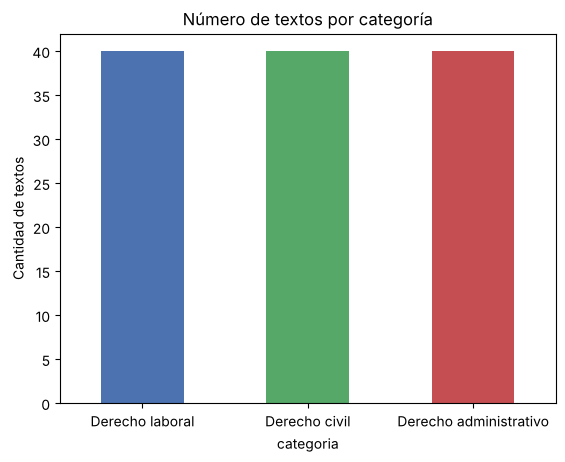

In [6]:
# Gráfico: distribución de categorías (verificamos que el corpus esté balanceado)
df["categoria"].value_counts().plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"])
plt.title("Número de textos por categoría")
plt.ylabel("Cantidad de textos")
plt.xticks(rotation=0)
plt.show()

## Paso 2. Preparación (procesamiento) de los textos

**Decisión del grupo – cómo preparar los textos:**

1. **Minúsculas:** "Contrato" y "contrato" deben ser la misma palabra.
2. **Quitar tildes:** evita que "petición" y "peticion" se cuenten distinto.
3. **Eliminar números y signos de puntuación:** no aportan a la categoría.
4. **Eliminar *stopwords*** (palabras vacías como *el, la, de, que, por*): aparecen en todos los textos y no ayudan a distinguir.

**Decisión del grupo – qué información utilizar:**
Solo usamos el **contenido textual** del documento. Las palabras propias de cada rama (por ejemplo *salario, cesantías, sindicato* → laboral; *arrendamiento, herencia, compraventa* → civil; *acto administrativo, entidad, licitación* → administrativo) son la información que el modelo aprende.

> Usamos una lista propia de stopwords en español para que el cuaderno funcione sin descargas adicionales.

In [7]:
STOPWORDS_ES = set('''
a al algo algunas algunos ante antes como con contra cual cuales cuando de del desde donde dos
el ella ellas ellos en entre era es esa esas ese eso esos esta estaba estado estan estar este esto estos
fue fueron ha han hasta hay la las le les lo los mas me mi mientras muy ni no nos o otra otro para pero
por porque que quien se sea segun ser si sin sobre su sus tambien tiene tienen todo todos tras un una uno unos
y ya yo hoy pues cada asi dicho dicha mismo misma cuyo cuya fin parte
'''.split())

def preparar_texto(texto):
    texto = texto.lower()                                        # 1. minúsculas
    texto = unicodedata.normalize("NFKD", texto)                  # 2. quitar tildes
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = re.sub(r"[^a-zñ\s]", " ", texto)                     # 3. quitar números y signos
    palabras = [p for p in texto.split()
                if p not in STOPWORDS_ES and len(p) > 2]          # 4. quitar stopwords
    return " ".join(palabras)

# Ejemplo: antes y después del procesamiento
ejemplo = df["texto"][0]
print("ORIGINAL :", ejemplo)
print("PROCESADO:", preparar_texto(ejemplo))

ORIGINAL : El trabajador fue despedido sin justa causa y solicita el pago de la indemnización prevista en el Código Sustantivo del Trabajo.
PROCESADO: trabajador despedido justa causa solicita pago indemnizacion prevista codigo sustantivo trabajo


In [8]:
df["texto_procesado"] = df["texto"].apply(preparar_texto)
df[["texto", "texto_procesado", "categoria"]].head()

,texto,texto_procesado,categoria
0,El trabajador fue despedido sin justa causa y ...,trabajador despedido justa causa solicita pago...,Derecho laboral
1,La empresa no ha consignado las cesantías del ...,empresa consignado cesantias ano anterior fond...,Derecho laboral
2,"Se reclama el pago de horas extras, recargos n...",reclama pago horas extras recargos nocturnos t...,Derecho laboral
3,El contrato de trabajo a término fijo fue term...,contrato trabajo termino fijo terminado vencim...,Derecho laboral
4,La trabajadora en estado de embarazo fue desvi...,trabajadora embarazo desvinculada autorizacion...,Derecho laboral


## Paso 3. Separación de datos y representación de los textos

### 3.1 Entrenamiento y prueba
Para **comprobar si la solución funciona** con textos que el modelo nunca ha visto, separamos los datos:

- **75 %** para **entrenar** el modelo.
- **25 %** para **probar** el modelo (el modelo no los ve durante el entrenamiento).

Se usa `stratify` para conservar la misma proporción de categorías en ambos grupos.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["texto_procesado"], df["categoria"],
    test_size=0.25, random_state=RANDOM_STATE, stratify=df["categoria"])

print("Textos de entrenamiento:", len(X_train))
print("Textos de prueba       :", len(X_test))

Textos de entrenamiento: 90
Textos de prueba       : 30


### 3.2 Representación: TF-IDF

Un modelo computacional no entiende palabras, solo números. Por eso convertimos cada texto en un **vector numérico** usando **TF-IDF** (*Term Frequency – Inverse Document Frequency*):

- **TF:** cuántas veces aparece una palabra en el documento.
- **IDF:** penaliza las palabras que aparecen en casi todos los documentos (poco informativas) y premia las que son características de pocos documentos.

**Decisión del grupo:** usamos **unigramas y bigramas** (`ngram_range=(1,2)`), de modo que el modelo capture expresiones jurídicas de dos palabras como *"acto administrativo"*, *"contrato trabajo"* o *"sociedad conyugal"*.

In [10]:
vectorizador = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vectorizador.fit_transform(X_train)   # aprende el vocabulario SOLO con entrenamiento
X_test_vec  = vectorizador.transform(X_test)

print("Dimensión de la matriz de entrenamiento:", X_train_vec.shape)
print("→ cada texto quedó representado por", X_train_vec.shape[1], "números (términos del vocabulario)")

# Vistazo a la representación del primer texto de entrenamiento
vocab = vectorizador.get_feature_names_out()
fila = X_train_vec[0].toarray().ravel()
top = fila.argsort()[::-1][:8]
pd.DataFrame({"término": vocab[top], "peso TF-IDF": fila[top].round(3)})

Dimensión de la matriz de entrenamiento: (90, 1285)
→ cada texto quedó representado por 1285 números (términos del vocabulario)


,término,peso TF-IDF
0,durante etapa,0.236
1,aprendiz sena,0.236
2,aprendiz,0.236
3,patrocinadora,0.236
4,retirado durante,0.236
5,alguna empresa,0.236
6,alguna,0.236
7,justificacion alguna,0.236


## Paso 4. Método de clasificación

**Decisión del grupo:** comparamos tres algoritmos clásicos de clasificación de textos, vistos en la práctica guiada:

| Modelo | Idea básica |
|---|---|
| **Naive Bayes Multinomial** | Calcula la probabilidad de cada categoría según las palabras que aparecen. |
| **Regresión Logística** | Asigna un peso a cada palabra y combina esos pesos para estimar la probabilidad de cada categoría. |
| **SVM lineal** | Busca la "frontera" que mejor separa las categorías en el espacio de vectores. |

Para elegir de forma justa usamos **validación cruzada de 5 particiones** sobre los datos de entrenamiento: el entrenamiento se divide en 5 partes, se entrena con 4 y se evalúa con 1, rotando 5 veces.

In [11]:
modelos = {
    "Naive Bayes":         MultinomialNB(),
    "Regresión Logística": LogisticRegression(max_iter=1000),
    "SVM lineal":          LinearSVC(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultados_cv = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                     ("modelo", modelo)])
    puntajes = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    resultados_cv[nombre] = puntajes
    print(f"{nombre:22s} exactitud promedio = {puntajes.mean():.2%}  (± {puntajes.std():.2%})")

Naive Bayes            exactitud promedio = 80.00%  (± 9.03%)
Regresión Logística    exactitud promedio = 81.11%  (± 8.31%)


SVM lineal             exactitud promedio = 82.22%  (± 7.37%)


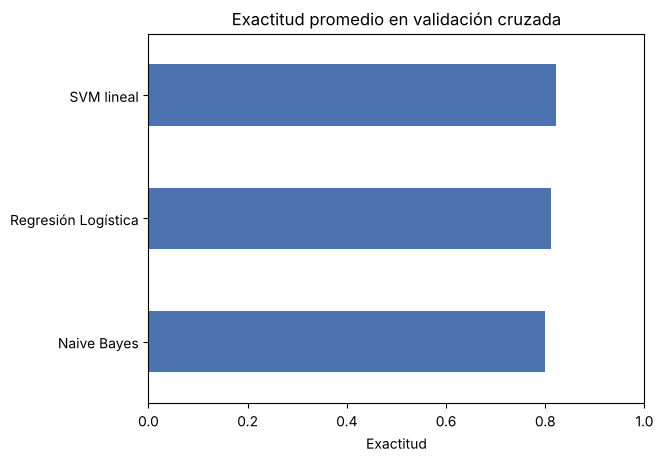

In [12]:
pd.DataFrame(resultados_cv).mean().sort_values().plot(kind="barh", color="#4C72B0")
plt.title("Exactitud promedio en validación cruzada")
plt.xlabel("Exactitud")
plt.xlim(0, 1)
plt.show()

**Modelo final:** elegimos **Regresión Logística**. Además de tener buen desempeño, ofrece dos ventajas importantes en un contexto jurídico:

1. Entrega una **probabilidad** por categoría (nivel de confianza), útil para saber cuándo enviar un documento a revisión humana.
2. Es **interpretable**: podemos ver qué palabras pesan más en cada decisión (explicabilidad).

> Si en su ejecución otro modelo obtiene un resultado claramente superior, pueden cambiar la elección y justificarla.

In [13]:
modelo_final = LogisticRegression(max_iter=1000)
modelo_final.fit(X_train_vec, y_train)
print("Modelo entrenado")

Modelo entrenado


## Paso 5. Evaluación: ¿la solución funciona?

Evaluamos el modelo con el **25 % de textos de prueba** que nunca vio. Métricas:

- **Exactitud (accuracy):** % de documentos bien clasificados.
- **Precisión:** de los que el modelo dijo que eran de una categoría, cuántos realmente lo eran.
- **Exhaustividad (recall):** de los que realmente eran de una categoría, cuántos encontró el modelo.
- **F1:** promedio armónico entre precisión y exhaustividad.
- **Matriz de confusión:** muestra en qué categorías se confunde.

In [14]:
y_pred = modelo_final.predict(X_test_vec)

print(f"Exactitud en datos de prueba: {accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred, digits=2))

Exactitud en datos de prueba: 80.00%



                        precision    recall  f1-score   support

Derecho administrativo       1.00      0.70      0.82        10
         Derecho civil       0.67      0.80      0.73        10
       Derecho laboral       0.82      0.90      0.86        10

              accuracy                           0.80        30
             macro avg       0.83      0.80      0.80        30
          weighted avg       0.83      0.80      0.80        30



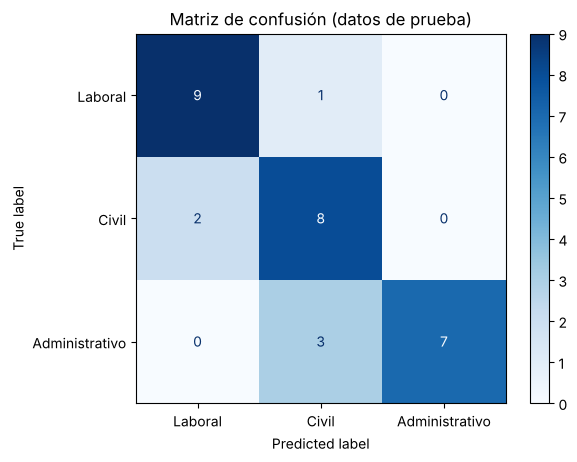

In [15]:
etiquetas = ["Derecho laboral", "Derecho civil", "Derecho administrativo"]
cm = confusion_matrix(y_test, y_pred, labels=etiquetas)
ConfusionMatrixDisplay(cm, display_labels=["Laboral", "Civil", "Administrativo"]).plot(cmap="Blues")
plt.title("Matriz de confusión (datos de prueba)")
plt.show()

### 5.1 ¿En qué se equivocó? (análisis de errores en datos de prueba)

In [16]:
prueba = pd.DataFrame({
    "texto": df.loc[X_test.index, "texto"],
    "real": y_test,
    "predicho": y_pred,
})
errores = prueba[prueba["real"] != prueba["predicho"]]
print("Número de errores en prueba:", len(errores), "de", len(prueba))
pd.set_option("display.max_colwidth", None)
errores

Número de errores en prueba: 6 de 30


,texto,real,predicho
57,Se solicita la declaración de unión marital de hecho y la existencia de la sociedad patrimonial entre compañeros permanentes.,Derecho civil,Derecho laboral
87,Se demanda la nulidad simple del decreto departamental por violar normas de superior jerarquía.,Derecho administrativo,Derecho civil
108,La secretaría de hacienda municipal cobra el impuesto predial mediante proceso de cobro coactivo.,Derecho administrativo,Derecho civil
98,La Contraloría inició proceso de responsabilidad fiscal por detrimento patrimonial en la ejecución de recursos públicos.,Derecho administrativo,Derecho civil
20,La EPS no ha pagado la licencia de maternidad a la trabajadora pese a estar al día en los aportes.,Derecho laboral,Derecho civil
60,El conductor del bus responde solidariamente con la empresa transportadora por las lesiones del pasajero.,Derecho civil,Derecho laboral


## Paso 6. Prueba con textos nuevos

La guía exige **al menos tres textos nuevos** que:
- **no** formen parte de los datos de entrenamiento,
- sean **suficientemente diferentes** de los ejemplos originales (redacción más larga, otro tipo de documento, otro vocabulario),
- representen alguna de las categorías.

Creamos **seis** textos: tres "claros" (uno por categoría) y tres "difíciles", para probar los límites del sistema.

> ✏️ El grupo puede reemplazar o agregar textos propios en la lista `textos_nuevos`.

In [17]:
textos_nuevos = [
    # 1. Laboral (claro) — formato de carta de reclamación
    ("Derecho laboral",
     "Señores Recursos Humanos: me permito manifestar mi inconformidad porque durante los últimos tres meses "
     "laboré turnos de doce horas, incluso los domingos, y en el desprendible de pago no aparece reconocido "
     "ningún recargo. Adicionalmente, nunca me entregaron copia del contrato que firmé al ingresar a la compañía."),

    # 2. Civil (claro) — conflicto entre particulares por un préstamo
    ("Derecho civil",
     "Mi hermano me prestó veinte millones de pesos para comprar un carro y firmamos una letra de cambio. "
     "Ya pasó la fecha acordada y no he podido devolverle el dinero; ahora él dice que va a cobrarme judicialmente "
     "y a pedir que me embarguen la moto."),

    # 3. Administrativo (claro) — actuación frente a una entidad pública
    ("Derecho administrativo",
     "El Instituto de Desarrollo Urbano de la ciudad negó mediante resolución la solicitud de la junta de acción comunal "
     "para pavimentar la vía del barrio, sin explicar los motivos. La comunidad quiere controvertir esa decisión "
     "porque considera que la autoridad actuó de manera arbitraria."),

    # 4. Laboral (difícil) — un empleado público: mezcla vocabulario laboral y administrativo
    ("Derecho laboral",
     "La docente vinculada a la secretaría de educación reclama que no le han pagado las vacaciones ni la prima "
     "de navidad del último año, y además le descontaron días de salario por una incapacidad médica."),

    # 5. Civil (difícil) — daño causado por una empresa privada, lenguaje coloquial
    ("Derecho civil",
     "Una tubería del edificio de al lado se rompió e inundó mi local, se dañaron los muebles y la mercancía. "
     "El administrador de ese edificio no quiere responder por los daños."),

    # 6. Administrativo (difícil) — redacción muy breve
    ("Derecho administrativo",
     "Me pusieron una fotomulta injusta y la secretaría de movilidad no me ha contestado."),
]

nuevos = pd.DataFrame(textos_nuevos, columns=["categoria_esperada", "texto"])

# Comprobación: ninguno de los textos nuevos está en los datos de entrenamiento
assert not nuevos["texto"].isin(df["texto"]).any()
print("Verificado: los textos nuevos NO están en el conjunto de datos de entrenamiento")

Verificado: los textos nuevos NO están en el conjunto de datos de entrenamiento


In [18]:
def clasificar(texto):
    """Flujo completo: texto jurídico → procesamiento → representación → modelo → categoría"""
    procesado = preparar_texto(texto)                 # procesamiento
    vector = vectorizador.transform([procesado])      # representación
    categoria = modelo_final.predict(vector)[0]       # modelo → categoría predicha
    probabilidades = modelo_final.predict_proba(vector)[0]
    return categoria, dict(zip(modelo_final.classes_, probabilidades))

filas = []
for i, fila in nuevos.iterrows():
    pred, probs = clasificar(fila["texto"])
    filas.append({
        "N°": i + 1,
        "esperada": fila["categoria_esperada"],
        "predicha": pred,
        "confianza": f"{max(probs.values()):.0%}",
        "¿acertó?": "✅" if pred == fila["categoria_esperada"] else "❌",
        **{f"P({k.replace('Derecho ', '')})": f"{v:.0%}" for k, v in probs.items()},
    })
tabla_nuevos = pd.DataFrame(filas)
tabla_nuevos

,N°,esperada,predicha,confianza,¿acertó?,P(administrativo),P(civil),P(laboral)
0,1,Derecho laboral,Derecho laboral,49%,✅,23%,28%,49%
1,2,Derecho civil,Derecho civil,40%,✅,30%,40%,30%
2,3,Derecho administrativo,Derecho administrativo,47%,✅,47%,26%,27%
3,4,Derecho laboral,Derecho laboral,43%,✅,27%,30%,43%
4,5,Derecho civil,Derecho civil,39%,✅,31%,39%,31%
5,6,Derecho administrativo,Derecho administrativo,40%,✅,40%,30%,30%


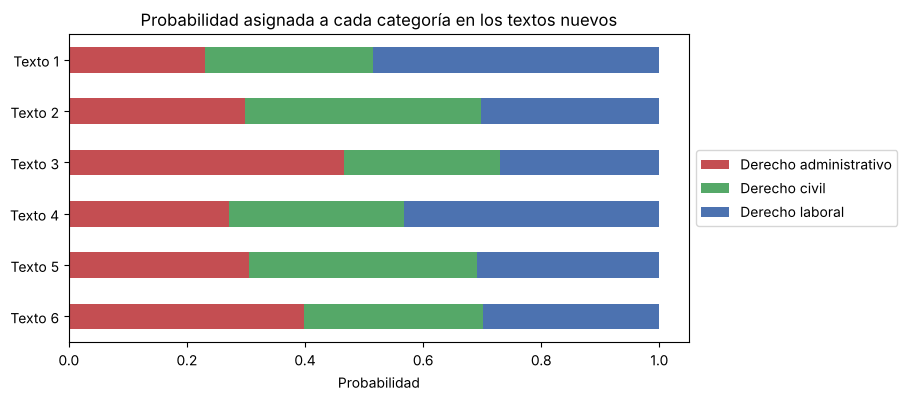

In [19]:
# Gráfico de probabilidades por texto nuevo
prob_df = pd.DataFrame([clasificar(t)[1] for t in nuevos["texto"]],
                       index=[f"Texto {i+1}" for i in range(len(nuevos))])
prob_df.plot(kind="barh", stacked=True, figsize=(8, 4),
             color={"Derecho administrativo": "#C44E52", "Derecho civil": "#55A868", "Derecho laboral": "#4C72B0"})
plt.title("Probabilidad asignada a cada categoría en los textos nuevos")
plt.xlabel("Probabilidad")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.gca().invert_yaxis()
plt.show()

### 6.1 Pruebe usted mismo
Escriba cualquier texto entre las comillas y ejecute la celda.

In [20]:
mi_texto = "El banco me cobró una cuota que no debía y quiero que me devuelvan el dinero del crédito."

categoria, probs = clasificar(mi_texto)
print("Categoría predicha:", categoria)
for k, v in sorted(probs.items(), key=lambda x: -x[1]):
    print(f"   {k:24s} {v:.0%}")

Categoría predicha: Derecho civil
   Derecho civil            45%
   Derecho laboral          27%
   Derecho administrativo   27%


## Paso 7. Interpretación de los resultados

### 7.1 ¿Qué palabras usa el modelo para decidir?
La Regresión Logística asigna un peso a cada término. Los de mayor peso son los que más "empujan" un texto hacia una categoría. Esto permite **explicar** las decisiones del modelo (requisito clave para usar IA en Derecho).

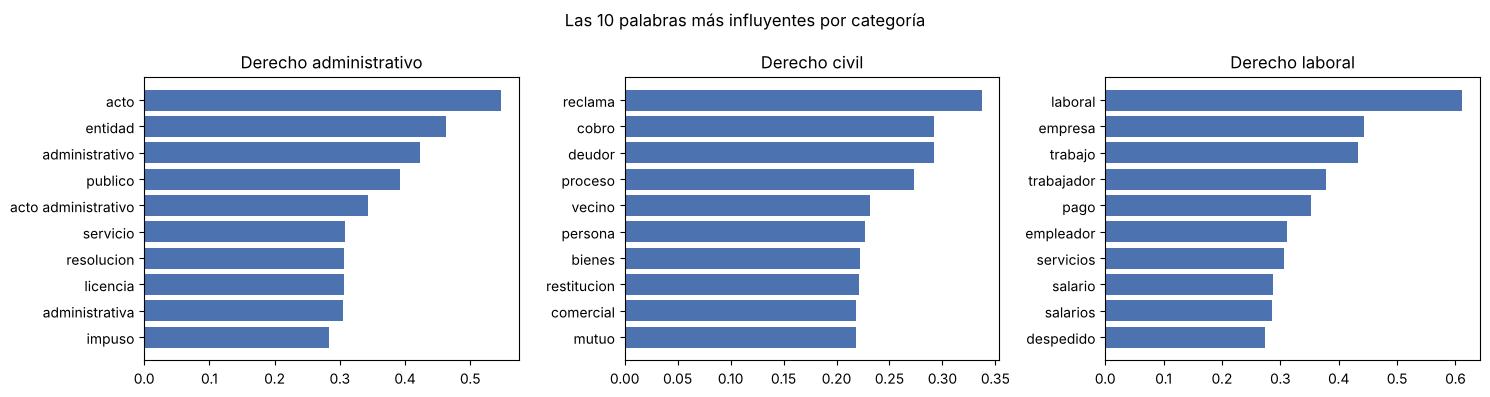

In [21]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, (i, clase) in zip(ejes, enumerate(modelo_final.classes_)):
    pesos = modelo_final.coef_[i]
    top = pesos.argsort()[::-1][:10]
    eje.barh(vocab[top][::-1], pesos[top][::-1], color="#4C72B0")
    eje.set_title(clase)
plt.suptitle("Las 10 palabras más influyentes por categoría")
plt.tight_layout()
plt.show()

In [22]:
# Explicación individual: ¿por qué el modelo clasificó así cada texto nuevo?
def explicar(texto, n=5):
    vector = vectorizador.transform([preparar_texto(texto)])
    pred = modelo_final.predict(vector)[0]
    i = list(modelo_final.classes_).index(pred)
    contrib = vector.toarray().ravel() * modelo_final.coef_[i]
    top = contrib.argsort()[::-1][:n]
    palabras = [vocab[j] for j in top if contrib[j] > 0]
    return pred, palabras

for i, t in enumerate(nuevos["texto"], 1):
    pred, palabras = explicar(t)
    print(f"Texto {i} → {pred:24s} palabras clave: {palabras if palabras else '(ninguna palabra conocida)'}")

Texto 1 → Derecho laboral          palabras clave: ['pago', 'durante', 'horas', 'turnos', 'contrato']
Texto 2 → Derecho civil            palabras clave: ['dinero', 'fecha']
Texto 3 → Derecho administrativo   palabras clave: ['resolucion', 'mediante', 'autoridad', 'motivos', 'mediante resolucion']
Texto 4 → Derecho laboral          palabras clave: ['salario', 'incapacidad', 'prima', 'vacaciones', 'ano']
Texto 5 → Derecho civil            palabras clave: ['local']
Texto 6 → Derecho administrativo   palabras clave: ['injusta', 'secretaria']


### 7.2 Interpretación de los resultados

> Los números de abajo corresponden a nuestra ejecución (semilla fija `RANDOM_STATE = 42`). Si en Colab varían levemente por la versión de las librerías, actualícenlos.

**Resultados generales.** El modelo clasificó correctamente **24 de 30 textos de prueba (80 % de exactitud)**, y en validación cruzada obtuvo un promedio similar (**≈ 81 %**). Que ambas cifras coincidan indica que el resultado es estable y no fruto de una partición afortunada. Para comparar: un sistema que adivine al azar acertaría el 33 %.

**Por categoría.**
- *Laboral* es la mejor reconocida (recall 90 %): su vocabulario es muy característico (*trabajador, salario, cesantías, pensión*).
- *Administrativo* tiene precisión del 100 % (cuando dice "administrativo", acierta) pero recall del 70 %: se le "escapan" textos administrativos que el modelo envía a civil.
- *Civil* es la categoría más confundida (precisión 67 %): funciona como "cajón de sastre" que recibe errores de las otras dos.

**¿En qué se equivocó? (6 errores en prueba)**
- **Administrativo → Civil (3 casos):** cobro coactivo del impuesto predial, responsabilidad fiscal de la Contraloría y nulidad simple de un decreto. Comparten palabras con el derecho civil (*cobro, patrimonial, responsabilidad, nulidad*); el modelo no sabe que quien actúa es una **autoridad pública**.
- **Civil → Laboral (2 casos):** la unión marital entre *compañeros permanentes* (expresión que también aparece en la pensión de sobrevivientes) y la responsabilidad de una *empresa* transportadora por un *conductor* (palabras típicas del mundo laboral).
- **Laboral → Civil (1 caso):** la licencia de maternidad no pagada por la EPS, donde dominan palabras como *pagado* y *aportes*.

**Textos nuevos.** Los **6 textos nuevos fueron clasificados correctamente**, incluidos los 3 "difíciles". Sin embargo, la **confianza fue baja (entre 39 % y 49 %)**: el modelo acierta, pero "duda". Esto se debe a que el corpus es pequeño y los textos nuevos usan vocabulario distinto (*fotomulta, tubería, letra de cambio*). En el texto 5 el modelo se apoyó prácticamente en una sola palabra (*local*), lo que muestra que el acierto fue frágil.

**Conclusión.** El modelo **no entiende el Derecho**: detecta patrones estadísticos de palabras. Funciona bien cuando el texto usa el léxico típico de cada rama, y falla cuando la clave está en **quién** actúa (particular vs. Estado) o cuando el vocabulario es compartido entre ramas.

## Paso 8. Respuestas para la presentación

**1. ¿Qué problema resolvimos?**
La clasificación manual de documentos jurídicos consume tiempo y genera inconsistencias. Construimos un prototipo que asigna automáticamente un documento a *Derecho laboral*, *civil* o *administrativo*.

**2. ¿Cómo lo resolvimos?**
Texto jurídico → **procesamiento** (minúsculas, sin tildes, sin signos, sin stopwords) → **representación** TF-IDF con unigramas y bigramas → **modelo** de Regresión Logística (elegido tras comparar con Naive Bayes y SVM) → **categoría predicha** con su nivel de confianza.

**3. ¿Qué resultados obtuvimos?**
- 80 % de exactitud en 30 textos de prueba (24 aciertos) y ≈ 81 % en validación cruzada (vs. 33 % del azar).
- Naive Bayes (80 %), Regresión Logística (81 %) y SVM (82 %) rindieron parecido; elegimos Regresión Logística porque da probabilidades y es explicable.
- Los 6 textos nuevos se clasificaron bien, pero con confianza baja (39 %–49 %).

**4. ¿En qué se equivocó?**
6 errores en prueba. El principal: textos administrativos de contenido económico (impuesto predial, responsabilidad fiscal, nulidad de un decreto) clasificados como civiles, porque el modelo se fija en palabras (*cobro, patrimonial, nulidad*) y no en que actúa una autoridad pública. También confundió civil y laboral cuando aparecían palabras como *empresa, conductor* o *compañeros permanentes*. En los textos nuevos acertó, pero con poca seguridad.

**5. ¿Podría utilizarse realmente en Derecho?**
**Sí, como herramienta de apoyo, no como sustituto del abogado.** Puede hacer un primer reparto (triaje) de documentos y enviar a revisión humana los casos con baja confianza. Para un uso real se necesitaría:
- un corpus mucho más grande y con documentos reales;
- más categorías (penal, familia, comercial, constitucional…) y la opción de que un documento pertenezca a varias;
- supervisión humana permanente, trazabilidad y explicabilidad de las decisiones;
- protección de datos personales (Ley 1581 de 2012) y lineamientos sobre uso responsable de IA en la justicia, como los fijados por la Corte Constitucional en la Sentencia T-323 de 2024.